In [2]:
import pandas as pd
import os
import numpy as np
from statistics import mean, stdev
from sklearn import preprocessing
from sklearn.model_selection import StratifiedKFold
from sklearn import linear_model
from sklearn import datasets
from sklearn.model_selection import GroupShuffleSplit


file_path = "/home/callum/projects/sno_analysis/data/processed"
file = "df_for_regression.csv"

df = pd.read_csv(os.path.join(file_path, file))

In [ ]:
df = pd.read_csv("/home/callum/projects/ub_predictor/data/processed/20261001_154827_sites_test/features_complete_readable.csv")
# df.rename(columns = {"ubiquitinated": "modified"}, inplace = True)
df.to_csv("/home/callum/projects/ub_predictor/data/processed/20261001_154827_sites_test/features_complete_readable.csv", index = False)

cols = ["sequence_k+6_is_Thr", "spatial_neighbour_9_is_Met", "spatial_neighbour_5_is_Ala", "sequence_k-3_is_Ala", "hydrophobic_residues_in_window", "net_charge_in_window", "mean_surface_exposure_c_terminal_half"]

df["modified"].value_counts()


np.int64(78)

In [5]:
print(df.columns)
df = df.iloc[:, 1:]

Index(['id', 'modified', 'position', 'sequence', 'hydrophobicity_5',
       'hydrophobicity_10', 'charge_5', 'charge_10', 'cluster_id',
       'pwm_pos_-3', 'pwm_pos_-2', 'pwm_pos_-1', 'pwm_pos_+1', 'pwm_pos_+2',
       'pwm_pos_+3'],
      dtype='str')


In [2]:
# Logistic regression

# split df into features and target variable
cols = "hydrophobicity_5 hydrophobicity_10 charge_5 charge_10 cluster_id pwm_pos_-3 pwm_pos_-2 pwm_pos_-1 pwm_pos_+1 pwm_pos_+2 pwm_pos_+3"
feature_cols = cols.split(" ")


In [9]:
# logistic regression can't handle NaNs, so i dropped them

print(df.shape)
df = df.dropna()

(5000, 14)


### Splitting data
train/test - split ratio dependent on:
- dataset size
- complexity and intricacy of model
When there are batches - treatments, homologous protein etc, grouping is required prior to train / test splitting




In [21]:
from sklearn.model_selection import GroupShuffleSplit
# initialise gss with 2 splits
gss = GroupShuffleSplit(n_splits=6, test_size=0.3, random_state=42)

# if one split - no need to loop:
train_idx, test_idx = next(gss.split(df, groups=df["cluster_id"]))
# this assigns each row to either test or split, returning index values of each row into one of the groups
print(train_idx)
train_data = df.iloc[train_idx]
test_data = df.iloc[test_idx]
# these get the actual data rows

X_train = train_data[feature_cols]
#take feature columns from training split
y_train = train_data["modified"]
X_test = test_data[feature_cols]
#take feature columns from test split
y_test = test_data["modified"]


#if > 1 split: do loop
# scores = []
# for train_idx, test_idx in gss.split(df, groups=df["cluster_id"]):
#     train_data = df.iloc[train_idx]
#     test_data = df.iloc[test_idx]

#     meta_cols = ["id", "cluster_id", "sequence", "position", "modified"]  # adjust to your column names
#     feature_cols = [c for c in df.columns if c not in meta_cols]
#     #assigning feature columns and metadata columns - maybe add number length test to ensure all are accounted for?

#     X_train = train_data[feature_cols]
#     #take feature columns from training split
#     y_train = train_data["modified"]
#     X_test = test_data[feature_cols]
#     #take feature columns from test split
#     y_test = test_data["modified"]
    
#     #scores.append()


# groups_train = train_data["cluster_id"]  # keep for GroupKFold if you tune hyperparameters

[   0    1    2 ... 4942 4944 4946]


In [23]:
# testing that train and test have similar  proportion of each class

assert set(train_data["cluster_id"]).isdisjoint(test_data["cluster_id"])
print(len(train_data), len(test_data))
print(y_train.value_counts(normalize=True), y_test.value_counts(normalize=True))

3436 1511
modified
0    0.82858
1    0.17142
Name: proportion, dtype: float64 modified
0    0.837194
1    0.162806
Name: proportion, dtype: float64


In [24]:
# import the class
from sklearn.linear_model import LogisticRegression

# instantiate the model (using the default parameters)
logreg = LogisticRegression(class_weight = "balanced", random_state=16)

# fit model to data
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)




In [17]:
from sklearn import metrics

cnf_matrix = metrics.confusion_matrix(y_test, y_pred)

print(cnf_matrix)

[[706 499]
 [ 99 154]]


Text(0.5, 427.9555555555555, 'Predicted label')

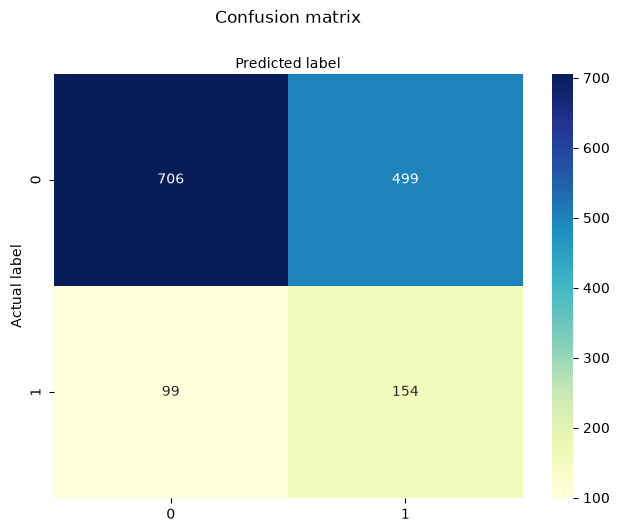

In [18]:
# import required modules
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')



In [25]:
from sklearn.metrics import classification_report
target_names = ['not modified', 'modified']
print(classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

not modified       0.88      0.60      0.71      1265
    modified       0.21      0.56      0.31       246

    accuracy                           0.59      1511
   macro avg       0.54      0.58      0.51      1511
weighted avg       0.77      0.59      0.65      1511



## Model evaluation
**accuracy** how many of model predictions are correct - takes true negatives and true positives into account - how often model makes correct prediction.

course-grained measure of model quality 

- issue using accuracy as metric is not as effective when using an imbalanced dataset

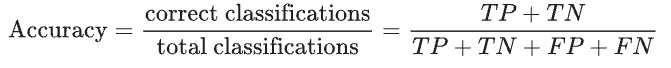

**precision** how many predictions labelled as positive are true positives 
- proportion of positive classifications vs true positives:

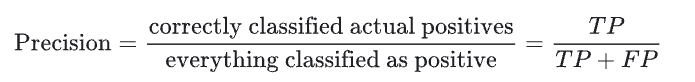

in imbalanced dataset that has low number of true positives, precision not as useful - better for balanced datasets

**Recall** - proportion of all real positives that were correctly classified

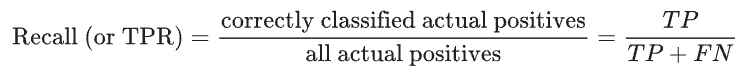

in imbalanced dataset with low number of positives, recall is useful metric - essentially asks what is the likelihood (fraction) that a true positive case will be detected


In [14]:
train_c = set(train_data["cluster_id"])
test_c = set(test_data["cluster_id"])
print("Shared clusters:", train_c & test_c)

train_p = set(train_data["id"])
test_p = set(test_data["id"])
print("Shared proteins:", train_p & test_p)

Shared clusters: set()
Shared proteins: set()


In [15]:
for c in X_train.columns:
    if X_train[c].nunique() < 50:
        purity = train_data.groupby(c)["modified"].nunique().max()
        if purity == 1:
            print("check:", c)

In [ ]:
print(feature_cols)
print("modified" in feature_cols)

NameError: name 'feature_cols' is not defined

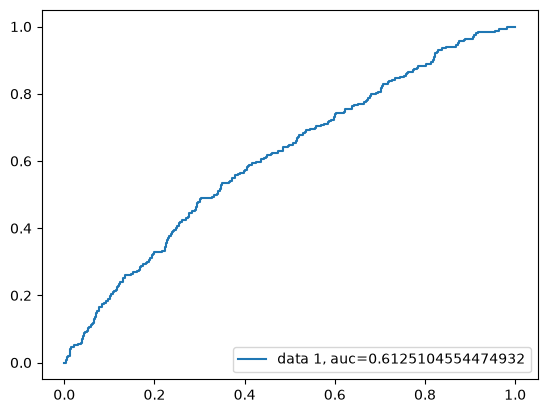

In [17]:
y_pred_proba = logreg.predict_proba(X_test)[::,1]
fpr, tpr, _ = metrics.roc_curve(y_test,  y_pred_proba)
auc = metrics.roc_auc_score(y_test, y_pred_proba)
plt.plot(fpr,tpr,label="data 1, auc="+str(auc))
plt.legend(loc=4)
plt.show()